# Lab 1 - Part 1: N-Gram Language Model

In [13]:
import math
import random
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.corpus import gutenberg

nltk.download("gutenberg", quiet=True)
nltk.download("punkt_tab", quiet=True)

random.seed(42)

## Data Preprocessing

In [21]:
def preprocess(text):
    sentences = []
    for sentence in nltk.sent_tokenize(text):
        sentence = sentence.lower()
        sentence = sentence.replace("'", "")             # call'd -> calld
        sentence = re.sub(r"[^a-z\s]", " ", sentence)    # remove punctuation and special characters
        tokens = sentence.split()                        # tokenize into words
        if tokens:
            sentences.append(tokens)
    return sentences


train_text = gutenberg.raw("shakespeare-caesar.txt") + "\n" + gutenberg.raw("shakespeare-macbeth.txt")
test_text = gutenberg.raw("shakespeare-hamlet.txt")

train_sentences = preprocess(train_text)
test_sentences = preprocess(test_text)

print("Train sentences:", len(train_sentences))
print("Test sentences:", len(test_sentences))
print("Example:", train_sentences[0])

Train sentences: 3033
Test sentences: 2355
Example: ['the', 'tragedie', 'of', 'julius', 'caesar', 'by', 'william', 'shakespeare', 'actus', 'primus']


## N-Gram Model
Laplace smoothing:

$$P(w \mid context) = \frac{count(context, w) + 1}{count(context) + V}$$

In [15]:
class NGramModel:
    def __init__(self, n):
        self.n = n
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.vocab = set()

    def get_ngrams(self, sentence):
        tokens = ["<s>"] * (self.n - 1) + sentence + ["</s>"]
        return [tuple(tokens[i:i + self.n]) for i in range(len(tokens) - self.n + 1)]

    def train(self, sentences):
        for sentence in sentences:
            self.vocab.update(sentence)
            for ngram in self.get_ngrams(sentence):
                self.ngram_counts[ngram] += 1
                self.context_counts[ngram[:-1]] += 1
        self.vocab.add("</s>")
        self.V = len(self.vocab) + 1   # +1 for unknown words

    def probability(self, ngram):
        context = ngram[:-1]
        return (self.ngram_counts[ngram] + 1) / (self.context_counts[context] + self.V)

    def perplexity(self, sentences):
        log_prob = 0
        N = 0
        for sentence in sentences:
            for ngram in self.get_ngrams(sentence):
                log_prob += math.log(self.probability(ngram))
                N += 1
        return math.exp(-log_prob / N)

    def generate(self, max_words=20):
        words = sorted(self.vocab)
        sentence = ["<s>"] * (self.n - 1)
        for _ in range(max_words):
            context = tuple(sentence[len(sentence) - (self.n - 1):])
            probs = [self.probability(context + (w,)) for w in words]
            next_word = random.choices(words, weights=probs)[0]
            if next_word == "</s>":
                break
            sentence.append(next_word)
        return " ".join(sentence[self.n - 1:])

## Unigram Baseline

In [29]:
unigram = NGramModel(1)
unigram.train(train_sentences)

print("Vocabulary size:", unigram.V)
print("Perplexity:", round(unigram.perplexity(test_sentences), 2))
print("Generated:", unigram.generate())

Vocabulary size: 5187
Perplexity: 812.87
Generated: i luc angerd children friends no cogitations cause a on close vp thy a confessd prize cass are whats my


## Comparing N-Gram Sizes (n = 1 to 10)

In [32]:
results = []
models = {}
for n in range(1, 11):
    model = NGramModel(n)
    model.train(train_sentences)
    models[n] = model
    results.append({"n": n, "perplexity": round(model.perplexity(test_sentences), 2)})

results = pd.DataFrame(results)
results

,n,perplexity
0,1,812.87
1,2,2578.80
2,3,4178.55
3,4,4337.42
4,5,4345.61
5,6,4346.32
6,7,4346.66
7,8,4346.66
8,9,4346.66
9,10,4346.66


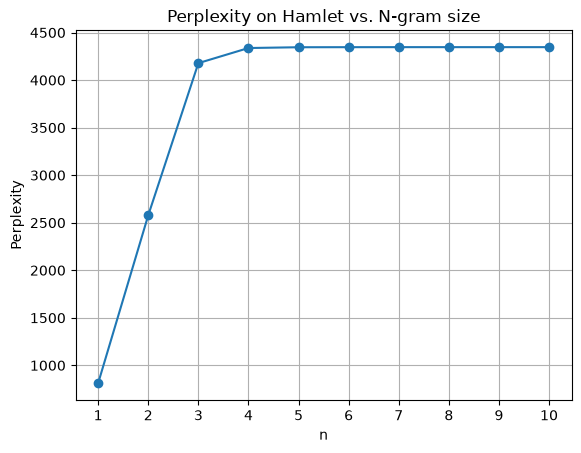

In [18]:
plt.plot(results["n"], results["perplexity"], marker="o")
plt.xlabel("n")
plt.ylabel("Perplexity")
plt.title("Perplexity on Hamlet vs. N-gram size")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

## Text Generation

In [35]:
for n in [1, 2, 3, 5, 10]:
    print(f"n = {n}:", models[n].generate())

n = 1: shall soldiours prophecying had a power for feare thou shall euer fantasie his him enter appeares how whereto rat vnreall
n = 2: omnes faculties mischieuous abhorred enuy husbanded noblenesse proceed kindnesse indirection dash la trickes sought conceptions bladed mad plebeians fond steps
n = 3: silence quickly demand croakes and disprooue ladder swinish being holds plaine cracks repetition likes disposd produce acheron sets signall bring
n = 5: i confounded wee maisters auouch does swet ioynd speakers purpose wounded on warne touching passion rung losse strings mischiefe treachery
n = 10: shewes lacke drenched diuellish popil shriekd mallice pindarus eating beseech entire eares fighting messala charme deuise remoue right beard herein
